# Ensemble Learning บน Iris: Bagging (Parallel) และ Boosting (Sequential)
**Classwork สุดท้าย · วิชา Machine Learning (รศ.ดร.ปริญญา สงวนสัตย์)**

ผู้ทำ: ปฏิมา ถิ่นสำราญ (6752300461) · รุจิรัตน์ แสงชัย (6752300739)

**โจทย์**: เขียน Bagging และ Boosting เองบนชุดข้อมูล Iris
- base classifier ใช้ `DecisionTreeClassifier` จาก sklearn (โจทย์อนุญาต)
- ตัวอัลกอริทึม ensemble เขียนเองทั้งหมดใน `ensemble.py` ด้วย NumPy
- Bagging เทรนแบบขนานด้วย `concurrent.futures.ProcessPoolExecutor` (built-in ของ Python)
- Boosting (AdaBoost SAMME) เทรนทีละรอบตามลำดับ

> **ทฤษฎี (เนื้อหาเสริม)**: สไลด์บท 03 Decision Tree กล่าวถึง Boosting ใน C5.0 สั้นๆ รายละเอียดด้านล่างเป็นเนื้อหาเสริม
> - **Bagging** (Bootstrap AGGregatING): สุ่มข้อมูลแบบใส่คืน B ชุด เทรนโมเดล 1 ตัวต่อชุด แล้วโหวตเสียงข้างมาก → ลด **variance** แต่ละโมเดลไม่ขึ้นต่อกัน จึงเทรนขนานได้
> - **AdaBoost SAMME**: เริ่มให้ทุกตัวอย่างมีน้ำหนัก 1/n ในแต่ละรอบ เทรน weak learner → หา weighted error ε → α = ln((1−ε)/ε) + ln(K−1) → เพิ่มน้ำหนักตัวที่ทายผิด w ← w·exp(α·[ผิด]) → ลด **bias** รอบ t ต้องรอน้ำหนักจากรอบ t−1 จึงต้องเป็น sequential
> - ทำนาย: H(x) = argmax_k Σ_t α_t·[h_t(x) = k]

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

from ensemble import BaggingClassifier, AdaBoostSAMME, accuracy, load_data

X_tr, X_te, y_tr, y_te, class_names = load_data()  # Iris จาก Hugging Face (antoniopelusi/iris), 70/30 stratified, seed 42
print("train", X_tr.shape, "test", X_te.shape, "classes", list(class_names))

train (105, 4) test (45, 4) classes [np.str_('Iris-setosa'), np.str_('Iris-versicolor'), np.str_('Iris-virginica')]


## 1. เปรียบเทียบความแม่นยำ
เทียบ ensemble กับ base classifier ตัวเดียวที่ใช้ข้างใน: Bagging เทียบกับ Decision Tree เต็มต้น, AdaBoost เทียบกับ Decision Stump

In [2]:
tree  = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
bag   = BaggingClassifier(n_estimators=50, parallel=True, seed=0).fit(X_tr, y_tr)
ada   = AdaBoostSAMME(n_estimators=50, seed=0).fit(X_tr, y_tr)

models = {"Decision Tree (single)": tree, "Bagging (50 trees)": bag,
          "Decision Stump (single)": stump, f"AdaBoost SAMME ({len(ada.alphas_)} stumps)": ada}
print(f"{'Model':<30}{'Train':>8}{'Test':>8}")
for name, m in models.items():
    print(f"{name:<30}{accuracy(y_tr, m.predict(X_tr)):>8.4f}{accuracy(y_te, m.predict(X_te)):>8.4f}")

Model                            Train    Test
Decision Tree (single)          0.9905  0.9333
Bagging (50 trees)              0.9905  0.9111
Decision Stump (single)         0.6667  0.6667
AdaBoost SAMME (50 stumps)      0.9905  0.9111


## 2. Accuracy ตามจำนวนโมเดลย่อย
เพราะ test set มีแค่ 45 ตัว ผลบน seed เดียวจึงแกว่ง กราฟ Bagging จึงเฉลี่ยจาก 10 seed

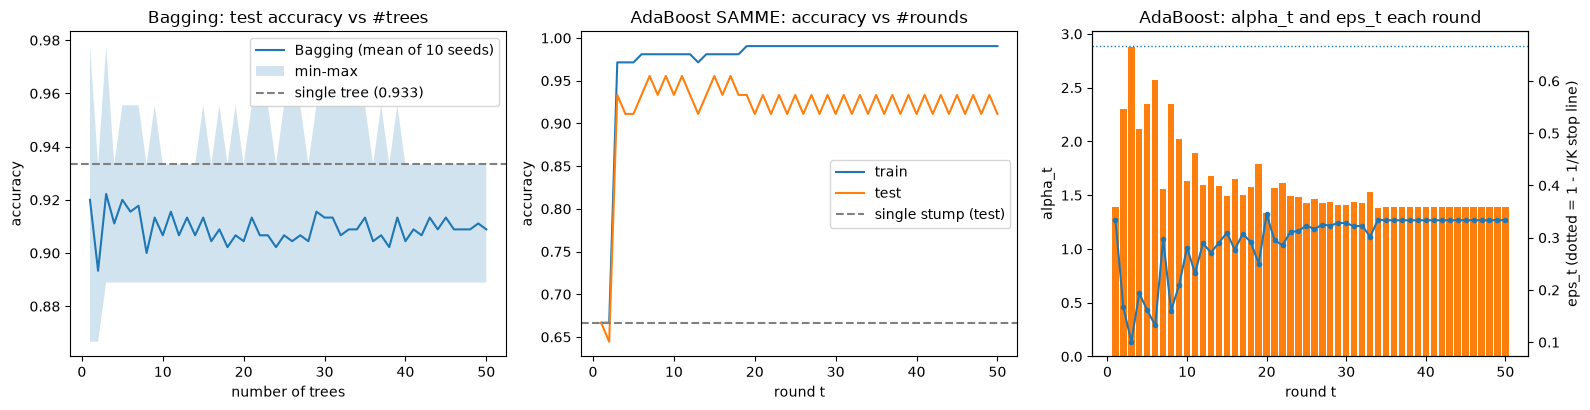

In [3]:
B = 50
bag_curves = np.array([BaggingClassifier(B, seed=s).fit(X_tr, y_tr).staged_score(X_te, y_te) for s in range(10)])
tree_acc = np.mean([accuracy(y_te, DecisionTreeClassifier(random_state=s).fit(X_tr, y_tr).predict(X_te)) for s in range(10)])

ada_test = ada.staged_score(X_te, y_te)
ada_train = ada.staged_score(X_tr, y_tr)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(1, B + 1)
ax[0].plot(x, bag_curves.mean(0), label="Bagging (mean of 10 seeds)")
ax[0].fill_between(x, bag_curves.min(0), bag_curves.max(0), alpha=.2, label="min-max")
ax[0].axhline(tree_acc, color="gray", ls="--", label=f"single tree ({tree_acc:.3f})")
ax[0].set(title="Bagging: test accuracy vs #trees", xlabel="number of trees", ylabel="accuracy")
ax[0].legend()

t = np.arange(1, len(ada.alphas_) + 1)
ax[1].plot(t, ada_train, label="train")
ax[1].plot(t, ada_test, label="test")
ax[1].axhline(accuracy(y_te, stump.predict(X_te)), color="gray", ls="--", label="single stump (test)")
ax[1].set(title="AdaBoost SAMME: accuracy vs #rounds", xlabel="round t", ylabel="accuracy")
ax[1].legend()

ax[2].bar(t, ada.alphas_, color="tab:orange", label="alpha_t")
ax2 = ax[2].twinx()
ax2.plot(t, ada.errors_, color="tab:blue", marker=".", label="weighted error eps_t")
ax2.axhline(1 - 1/3, color="tab:blue", ls=":", lw=1)
ax[2].set(title="AdaBoost: alpha_t and eps_t each round", xlabel="round t", ylabel="alpha_t")
ax2.set_ylabel("eps_t (dotted = 1 - 1/K stop line)")
fig.tight_layout(); plt.show()

## 3. Bagging: Parallel vs Sequential
จับเวลาการ `fit` ของ Bagging แบบขนาน (ProcessPoolExecutor) เทียบกับแบบวนลูปธรรมดา

B=   10  parallel 1.905s   sequential 0.007s


B=   50  parallel 1.897s   sequential 0.033s


B=  200  parallel 1.905s   sequential 0.123s


B= 1000  parallel 1.952s   sequential 0.624s


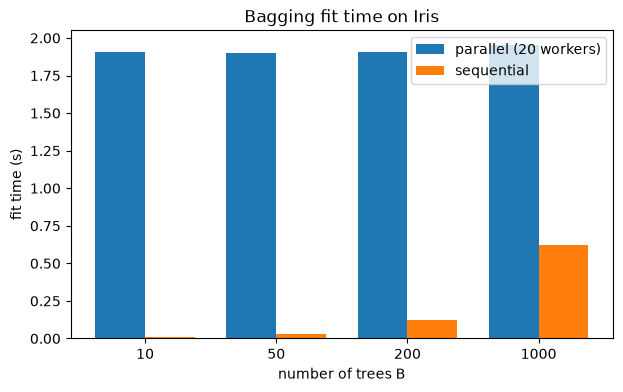

In [4]:
import os
sizes = [10, 50, 200, 1000]
t_par, t_seq = [], []
for b in sizes:
    t0 = time.perf_counter(); BaggingClassifier(b, parallel=True,  seed=0).fit(X_tr, y_tr); t_par.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); BaggingClassifier(b, parallel=False, seed=0).fit(X_tr, y_tr); t_seq.append(time.perf_counter() - t0)
    print(f"B={b:5d}  parallel {t_par[-1]:.3f}s   sequential {t_seq[-1]:.3f}s")

w = 0.38; xi = np.arange(len(sizes))
plt.figure(figsize=(7, 4))
plt.bar(xi - w/2, t_par, w, label=f"parallel ({os.cpu_count()} workers)")
plt.bar(xi + w/2, t_seq, w, label="sequential")
plt.xticks(xi, sizes); plt.xlabel("number of trees B"); plt.ylabel("fit time (s)")
plt.title("Bagging fit time on Iris"); plt.legend(); plt.show()

## 4. Confusion matrix บน test set

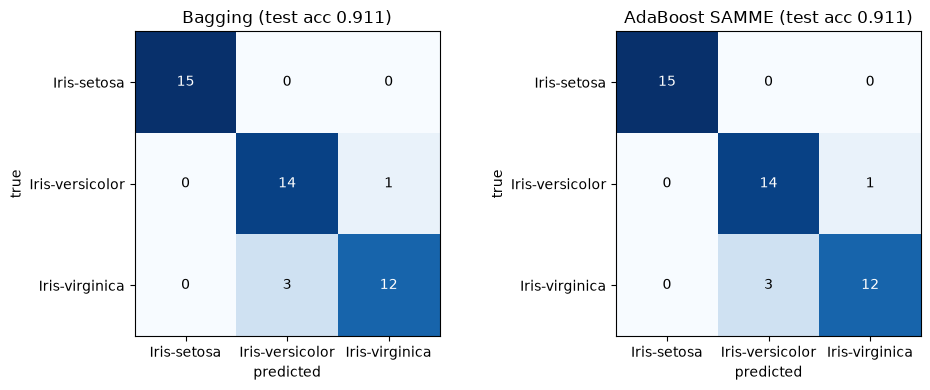

In [5]:
def confusion(y, p, K=3):
    cm = np.zeros((K, K), int)
    np.add.at(cm, (y, p), 1)  # แถว = class จริง, คอลัมน์ = class ที่ทาย
    return cm

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, [("Bagging", bag), ("AdaBoost SAMME", ada)]):
    cm = confusion(y_te, m.predict(X_te))
    a.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    a.set(title=f"{name} (test acc {accuracy(y_te, m.predict(X_te)):.3f})", xlabel="predicted", ylabel="true",
          xticks=range(3), yticks=range(3), xticklabels=class_names, yticklabels=class_names)
fig.tight_layout(); plt.show()

## 5. วิเคราะห์ผล (เขียนเอง)
แนวคำถามที่ควรตอบจากผลด้านบน:
1. Bagging ดีกว่า Decision Tree ต้นเดียวไหม? ทำไม Iris ถึงเห็นผลต่างน้อย (ข้อมูลง่าย, test มี 45 ตัว 1 ตัว = 2.2%)
2. AdaBoost ยกระดับ stump (accuracy ~0.67) ขึ้นมาได้เท่าไหร่ และ train accuracy ทำตัวอย่างไรตามจำนวนรอบ
3. ค่า α_t สัมพันธ์กับ ε_t อย่างไร
4. ทำไม parallel ช้ากว่า sequential บน Iris (ค่าใช้จ่ายการสร้าง process และส่งข้อมูลข้าม process มากกว่างานเทรน DT ที่ใช้เวลาไม่ถึงมิลลิวินาที) แล้ว parallel จะคุ้มเมื่อไหร่
5. class ไหนสับสนกันบ่อยที่สุดใน confusion matrix